# E-commerce Customer Behaviour: EDA, Segmentation & Churn

An analysis of 350 e-commerce customers: who they are, how they spend, which natural customer segments exist, and whether we can predict which customers are about to churn.

**Notebook outline**
1. Load and clean the data
2. Data-quality audit (duplicates and hidden structure)
3. Exploratory analysis
4. Customer segmentation with K-Means
5. Churn prediction, evaluated honestly
6. Key findings

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
SHOTS = Path("screenshots"); SHOTS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=1.0)
MEMBER_COLORS = {"Gold": "#d4a017", "Silver": "#9aa5b1", "Bronze": "#b0703c"}
SAT_ORDER = ["Satisfied", "Neutral", "Unsatisfied"]
SAT_COLORS = {"Satisfied": "#16a34a", "Neutral": "#f59e0b", "Unsatisfied": "#dc2626"}

## 1. Load and clean the data

In [2]:
df = pd.read_csv("data/ecommerce_customer_behavior.csv")
df.columns = [c.strip().replace(" ", "_") for c in df.columns]
print(df.shape)
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
df.head()

(350, 11)
Missing values:
 Satisfaction_Level    2
dtype: int64


,Customer_ID,Gender,Age,City,Membership_Type,Total_Spend,Items_Purchased,Average_Rating,Discount_Applied,Days_Since_Last_Purchase,Satisfaction_Level
0,101,Female,29,New York,Gold,1120.20,14,4.6,True,25,Satisfied
1,102,Male,34,Los Angeles,Silver,780.50,11,4.1,False,18,Neutral
2,103,Female,43,Chicago,Bronze,510.75,9,3.4,True,42,Unsatisfied
3,104,Male,30,San Francisco,Gold,1480.30,19,4.7,False,12,Satisfied
4,105,Male,27,Miami,Silver,720.40,13,4.0,True,55,Unsatisfied


In [3]:
# The only missing values are 2 Satisfaction_Level entries; fill with the most common level for that membership tier
df["Satisfaction_Level"] = df["Satisfaction_Level"].fillna(
    df.groupby("Membership_Type")["Satisfaction_Level"].transform(lambda s: s.mode()[0]))
df["Discount_Applied"] = df["Discount_Applied"].astype(bool)

# Churn definition (recency-based): no purchase in the last 30 days
df["Churned"] = (df["Days_Since_Last_Purchase"] > 30).astype(int)
print(df["Churned"].value_counts().rename({0: "Active", 1: "Churned"}))

Churned
Active     226
Churned    124
Name: count, dtype: int64


## 2. Data-quality audit

Before modelling, it's worth checking how many customers are genuinely different, and whether some columns are just copies of others.

In [4]:
profile_cols = [c for c in df.columns if c != "Customer_ID"]
df["Profile_ID"] = df.groupby(profile_cols, sort=False).ngroup()
n_unique = df["Profile_ID"].nunique()
print(f"Rows: {len(df)}  |  unique customer profiles: {n_unique}  |  exact duplicates (ignoring ID): {len(df) - n_unique}")
print()
print("City -> Membership type:")
print(pd.crosstab(df["City"], df["Membership_Type"]))

Rows: 350  |  unique customer profiles: 170  |  exact duplicates (ignoring ID): 180

City -> Membership type:
Membership_Type  Bronze  Gold  Silver
City                                 
Chicago              58     0       0
Houston              58     0       0
Los Angeles           0     0      59
Miami                 0     0      58
New York              0    59       0
San Francisco         0    58       0


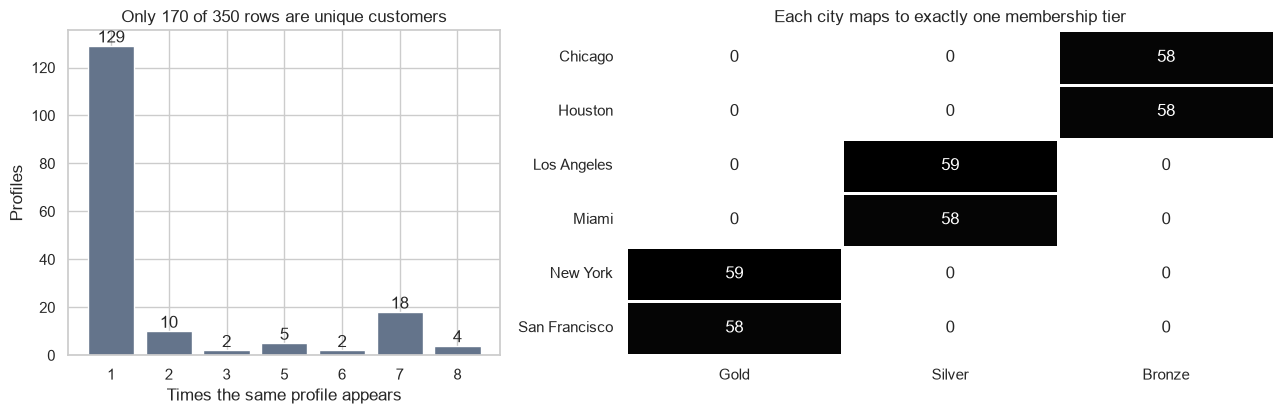

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [1, 1.5]})
copies = df["Profile_ID"].value_counts().value_counts().sort_index()
axes[0].bar(copies.index.astype(str), copies.values, color="#64748b")
axes[0].bar_label(axes[0].containers[0])
axes[0].set_xlabel("Times the same profile appears"); axes[0].set_ylabel("Profiles")
axes[0].set_title(f"Only {n_unique} of {len(df)} rows are unique customers")
ct = pd.crosstab(df["City"], df["Membership_Type"])[["Gold", "Silver", "Bronze"]]
sns.heatmap(ct, annot=True, fmt="d", cmap="Greys", cbar=False, ax=axes[1], linewidths=1)
axes[1].set_title("Each city maps to exactly one membership tier"); axes[1].set_xlabel(""); axes[1].set_ylabel("")
plt.tight_layout(); plt.savefig(SHOTS / "data_quality.png", dpi=110); plt.show()

**Takeaways**
- About half the rows are duplicated profiles with a new customer ID. Any random train/test split would put identical customers on both sides, so the modelling below **groups duplicates together**.
- `City` and `Membership_Type` carry the same information, which points to a synthetic dataset. Conclusions about real-world behaviour should be drawn carefully.

## 3. Exploratory analysis

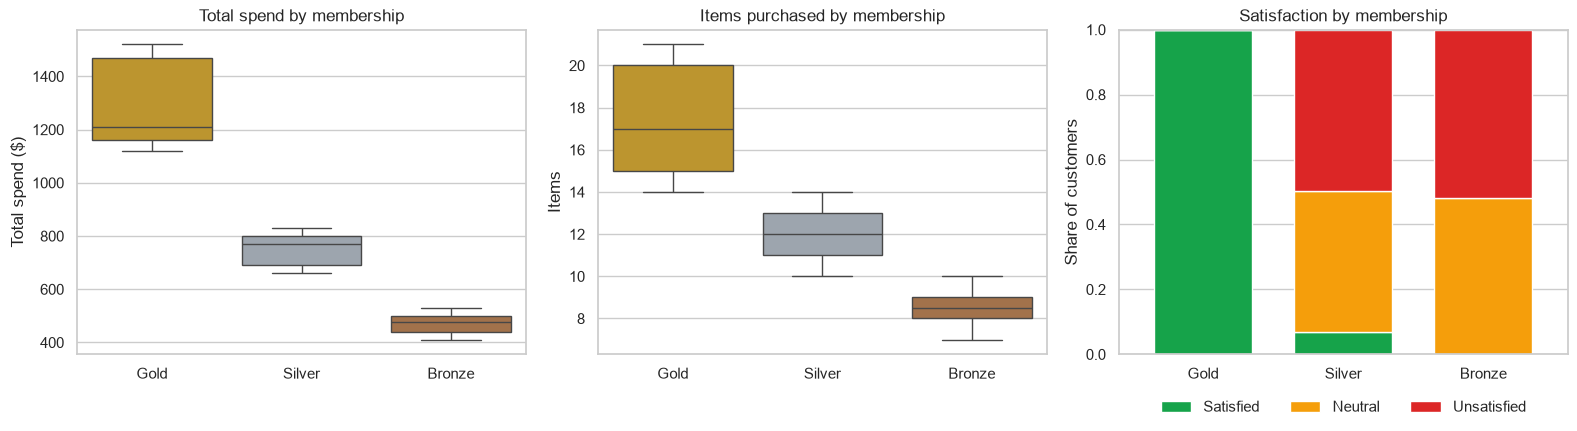

                 Total_Spend  Items_Purchased  Average_Rating  \
Membership_Type                                                 
Gold                  1311.1             17.6             4.7   
Silver                 748.4             11.7             4.1   
Bronze                 473.4              8.5             3.3   

                 Days_Since_Last_Purchase   Age  
Membership_Type                                  
Gold                                 17.9  29.9  
Silver                               30.3  31.6  
Bronze                               31.6  39.4  


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
order = ["Gold", "Silver", "Bronze"]
sns.boxplot(data=df, x="Membership_Type", y="Total_Spend", order=order, hue="Membership_Type",
            palette=MEMBER_COLORS, ax=axes[0], legend=False)
axes[0].set_title("Total spend by membership"); axes[0].set_xlabel(""); axes[0].set_ylabel("Total spend ($)")
sns.boxplot(data=df, x="Membership_Type", y="Items_Purchased", order=order, hue="Membership_Type",
            palette=MEMBER_COLORS, ax=axes[1], legend=False)
axes[1].set_title("Items purchased by membership"); axes[1].set_xlabel(""); axes[1].set_ylabel("Items")
sat = pd.crosstab(df["Membership_Type"], df["Satisfaction_Level"], normalize="index").loc[order, SAT_ORDER]
sat.plot(kind="bar", stacked=True, ax=axes[2], color=[SAT_COLORS[s] for s in SAT_ORDER], rot=0, width=0.7)
axes[2].set_title("Satisfaction by membership"); axes[2].set_xlabel(""); axes[2].set_ylabel("Share of customers")
axes[2].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(SHOTS / "membership_overview.png", dpi=110); plt.show()

print(df.groupby("Membership_Type")[["Total_Spend", "Items_Purchased", "Average_Rating",
                                     "Days_Since_Last_Purchase", "Age"]].mean().loc[order].round(1))

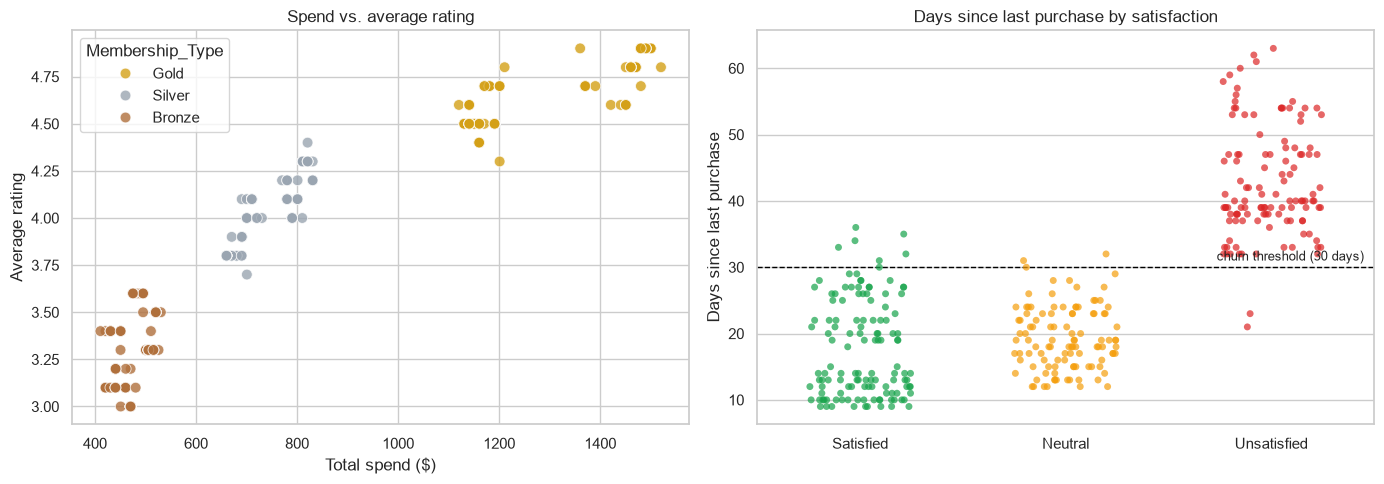

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="Total_Spend", y="Average_Rating", hue="Membership_Type", hue_order=order,
                palette=MEMBER_COLORS, s=60, alpha=0.8, ax=axes[0], edgecolor="white")
axes[0].set_title("Spend vs. average rating"); axes[0].set_xlabel("Total spend ($)"); axes[0].set_ylabel("Average rating")
sns.stripplot(data=df, x="Satisfaction_Level", y="Days_Since_Last_Purchase", order=SAT_ORDER, hue="Satisfaction_Level",
              palette=SAT_COLORS, jitter=0.25, alpha=0.7, ax=axes[1], legend=False)
axes[1].axhline(30, color="black", ls="--", lw=1); axes[1].text(2.45, 31, "churn threshold (30 days)", ha="right", fontsize=9)
axes[1].set_title("Days since last purchase by satisfaction"); axes[1].set_xlabel(""); axes[1].set_ylabel("Days since last purchase")
plt.tight_layout(); plt.savefig(SHOTS / "spend_rating_recency.png", dpi=110); plt.show()

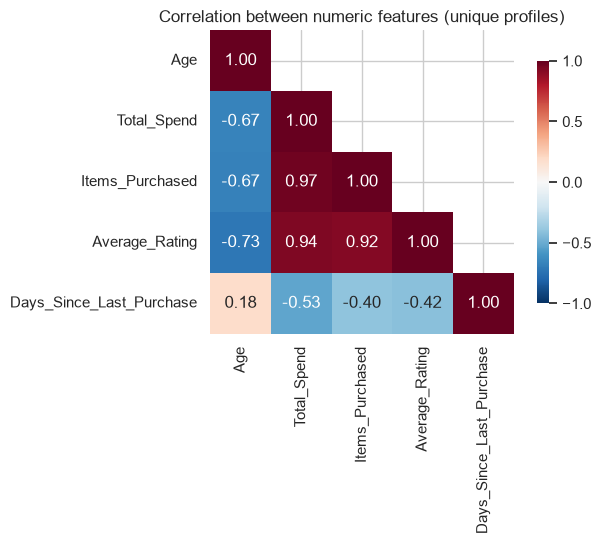

In [8]:
num = ["Age", "Total_Spend", "Items_Purchased", "Average_Rating", "Days_Since_Last_Purchase"]
corr = df.drop_duplicates("Profile_ID")[num].corr()
plt.figure(figsize=(7, 5.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr), 1),
            square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation between numeric features (unique profiles)")
plt.tight_layout(); plt.savefig(SHOTS / "correlation.png", dpi=110); plt.show()

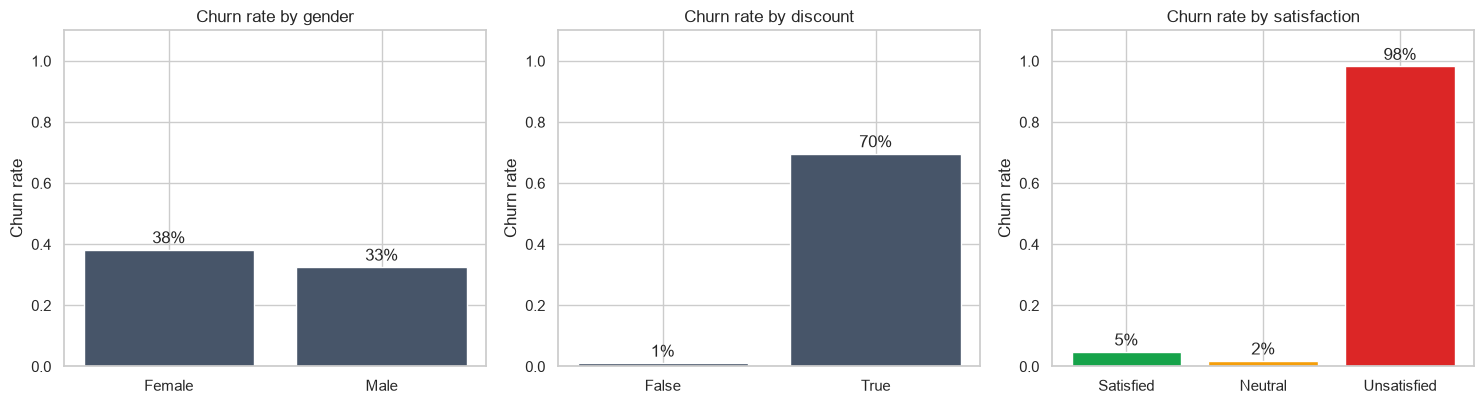

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, title in [(axes[0], "Gender", "Churn rate by gender"), (axes[1], "Discount_Applied", "Churn rate by discount"),
                       (axes[2], "Satisfaction_Level", "Churn rate by satisfaction")]:
    rate = df.groupby(col)["Churned"].mean()
    if col == "Satisfaction_Level":
        rate = rate.reindex(SAT_ORDER); colors = [SAT_COLORS[s] for s in rate.index]
    else:
        colors = "#475569"
    bars = ax.bar(rate.index.astype(str), rate.values, color=colors)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in rate.values], padding=2)
    ax.set_ylim(0, 1.1); ax.set_title(title); ax.set_ylabel("Churn rate"); ax.set_xlabel("")
plt.tight_layout(); plt.savefig(SHOTS / "churn_drivers.png", dpi=110); plt.show()

## 4. Customer segmentation (K-Means)

Customers are clustered on their behaviour (spend, items, rating, recency and age) using the **unique profiles** only, so duplicates don't distort the clusters.

The silhouette score keeps rising as k grows, because this synthetic data contains many tight, repeated groups, so it doesn't give a clear answer. **k = 4** is used instead: it's where the elbow curve flattens, and it gives four segments that are distinct and actionable.

Silhouette by k: {2: 0.475, 3: 0.487, 4: 0.543, 5: 0.602, 6: 0.65, 7: 0.691} -> chosen k = 4


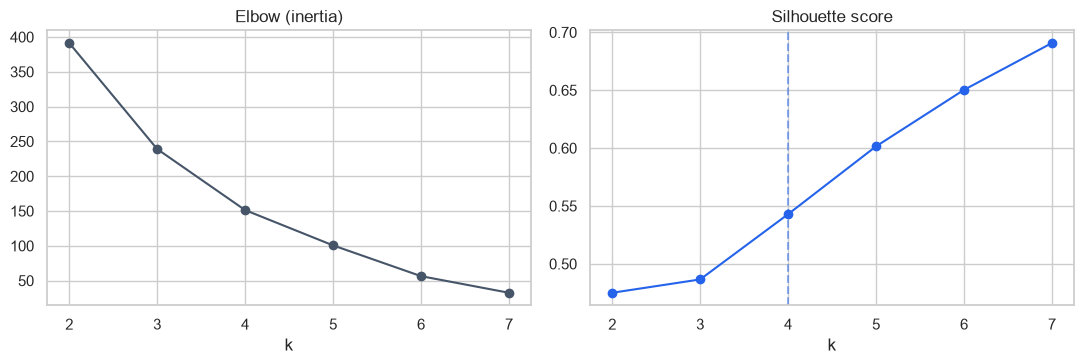

In [10]:
profiles = df.drop_duplicates("Profile_ID").reset_index(drop=True)
seg_features = ["Total_Spend", "Items_Purchased", "Average_Rating", "Days_Since_Last_Purchase", "Age"]
Xs = StandardScaler().fit_transform(profiles[seg_features])

ks = range(2, 8)
sil = [silhouette_score(Xs, KMeans(k, n_init=20, random_state=SEED).fit_predict(Xs)) for k in ks]
inertia = [KMeans(k, n_init=20, random_state=SEED).fit(Xs).inertia_ for k in ks]
best_k = 4
print("Silhouette by k:", {k: round(float(v), 3) for k, v in zip(ks, sil)}, "-> chosen k =", best_k)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(list(ks), inertia, "o-", color="#475569"); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sil, "o-", color="#2563eb"); axes[1].axvline(best_k, ls="--", color="#2563eb", alpha=0.5)
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.savefig(SHOTS / "choosing_k.png", dpi=110); plt.show()

In [11]:
km = KMeans(best_k, n_init=20, random_state=SEED).fit(Xs)
profiles["Segment"] = km.labels_
summary = profiles.groupby("Segment").agg(
    Customers=("Profile_ID", "size"), Avg_spend=("Total_Spend", "mean"), Avg_items=("Items_Purchased", "mean"),
    Avg_rating=("Average_Rating", "mean"), Avg_days_inactive=("Days_Since_Last_Purchase", "mean"),
    Avg_age=("Age", "mean"), Churn_rate=("Churned", "mean"),
    Main_tier=("Membership_Type", lambda s: s.mode()[0])).round(2)

# Name segments by their spend and recency
def name(row):
    if row.Avg_spend > 1100: return "VIP spenders"
    if row.Churn_rate >= 0.9: return "Lapsed mid spenders"
    if row.Churn_rate <= 0.05: return "Engaged mid spenders"
    return "Budget shoppers"
summary["Segment_name"] = summary.apply(name, axis=1)
profiles["Segment_name"] = profiles["Segment"].map(summary["Segment_name"])
summary.sort_values("Avg_spend", ascending=False)

,Customers,Avg_spend,Avg_items,Avg_rating,Avg_days_inactive,Avg_age,Churn_rate,Main_tier,Segment_name
Segment,,,,,,,,,
1,54,1302.90,17.44,4.66,19.54,30.06,0.11,Gold,VIP spenders
3,27,801.33,11.59,4.18,16.26,34.04,0.00,Silver,Engaged mid spenders
2,28,689.31,11.68,3.93,47.21,29.11,1.00,Silver,Lapsed mid spenders
0,61,473.46,8.48,3.33,33.38,39.41,0.54,Bronze,Budget shoppers


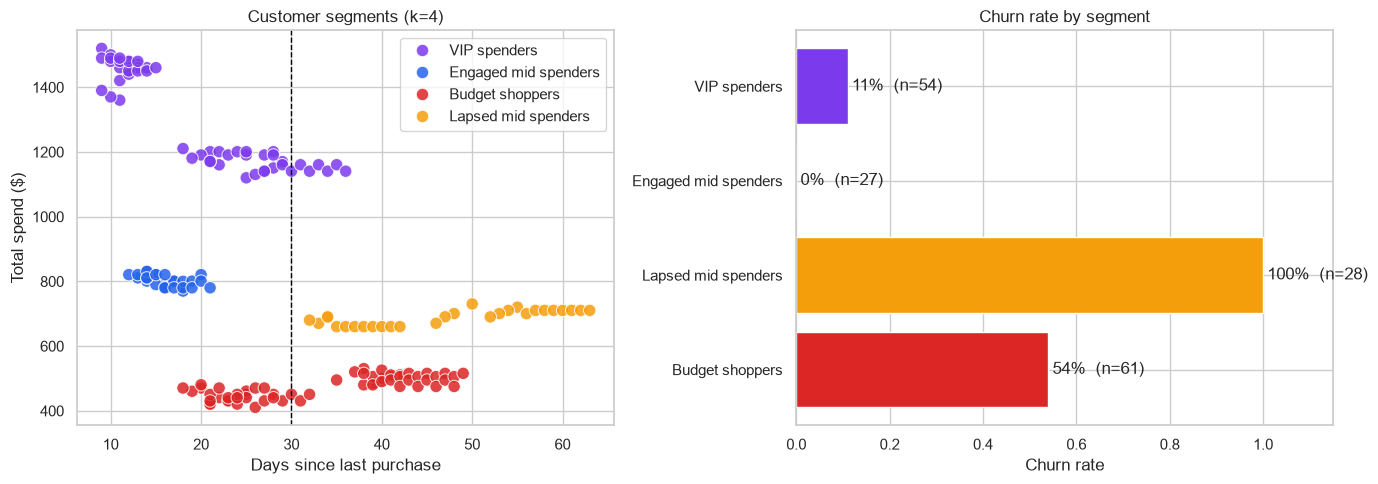

In [12]:
seg_palette = dict(zip(summary.sort_values("Avg_spend", ascending=False)["Segment_name"],
                       ["#7c3aed", "#2563eb", "#f59e0b", "#dc2626", "#16a34a", "#64748b"]))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=profiles, x="Days_Since_Last_Purchase", y="Total_Spend", hue="Segment_name", palette=seg_palette,
                s=80, alpha=0.85, edgecolor="white", ax=axes[0])
axes[0].axvline(30, color="black", ls="--", lw=1)
axes[0].set_title(f"Customer segments (k={best_k})"); axes[0].set_xlabel("Days since last purchase"); axes[0].set_ylabel("Total spend ($)")
axes[0].legend(title="", frameon=True)
s = summary.set_index("Segment_name").sort_values("Avg_spend", ascending=False)
bars = axes[1].barh(s.index, s["Churn_rate"], color=[seg_palette[n] for n in s.index])
axes[1].bar_label(bars, labels=[f"{v:.0%}  (n={n})" for v, n in zip(s["Churn_rate"], s["Customers"])], padding=3)
axes[1].set_xlim(0, 1.15); axes[1].invert_yaxis(); axes[1].set_title("Churn rate by segment"); axes[1].set_xlabel("Churn rate")
plt.tight_layout(); plt.savefig(SHOTS / "segments.png", dpi=110); plt.show()

## 5. Churn prediction, evaluated honestly

**Target:** `Churned` = more than 30 days since the last purchase. `Days_Since_Last_Purchase` is removed from the features, because it *defines* the target.

**Evaluation:** models are trained and tested on the **170 unique profiles** with stratified 5-fold cross-validation, so no customer appears in both training and test data.

**Baseline:** a one-line business rule, *"predict churn if the customer is Unsatisfied"*. A model is only useful if it beats this.

In [13]:
data = profiles.copy()
y = data["Churned"]
cat = ["Gender", "City", "Membership_Type", "Satisfaction_Level", "Discount_Applied"]
numf = ["Age", "Total_Spend", "Items_Purchased", "Average_Rating"]

def make_prep(cats, nums):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cats), ("num", StandardScaler(), nums)])

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=5, random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(max_depth=2, n_estimators=100, learning_rate=0.1, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def evaluate(cats, nums, label):
    rows = []
    for name, model in models.items():
        pipe = make_pipeline(make_prep(cats, nums), model)
        proba = cross_val_predict(pipe, data[cats + nums], y, cv=cv, method="predict_proba")[:, 1]
        pred = (proba >= 0.5).astype(int)
        rows.append({"Features": label, "Model": name, "Accuracy": (pred == y).mean(),
                     "Recall (churners caught)": pred[y == 1].mean(), "ROC AUC": roc_auc_score(y, proba)})
    return rows

rule = (data["Satisfaction_Level"] == "Unsatisfied").astype(int)
rows = [{"Features": "Rule", "Model": "Rule: Unsatisfied -> churn", "Accuracy": (rule == y).mean(),
         "Recall (churners caught)": rule[y == 1].mean(), "ROC AUC": roc_auc_score(y, rule)}]
rows += evaluate(cat, numf, "All features")
cat_no_sat = [c for c in cat if c != "Satisfaction_Level"]
rows += evaluate(cat_no_sat, numf, "Without satisfaction")
res = pd.DataFrame(rows)
res.round(3)

,Features,Model,Accuracy,Recall (churners caught),ROC AUC
0,Rule,Rule: Unsatisfied -> churn,0.941,0.881,0.931
1,All features,Logistic Regression,0.953,0.881,0.972
2,All features,Random Forest,0.953,0.881,0.982
3,All features,Gradient Boosting,0.918,0.925,0.980
4,Without satisfaction,Logistic Regression,0.953,0.881,0.974
5,Without satisfaction,Random Forest,0.953,0.881,0.984
6,Without satisfaction,Gradient Boosting,0.924,0.925,0.983


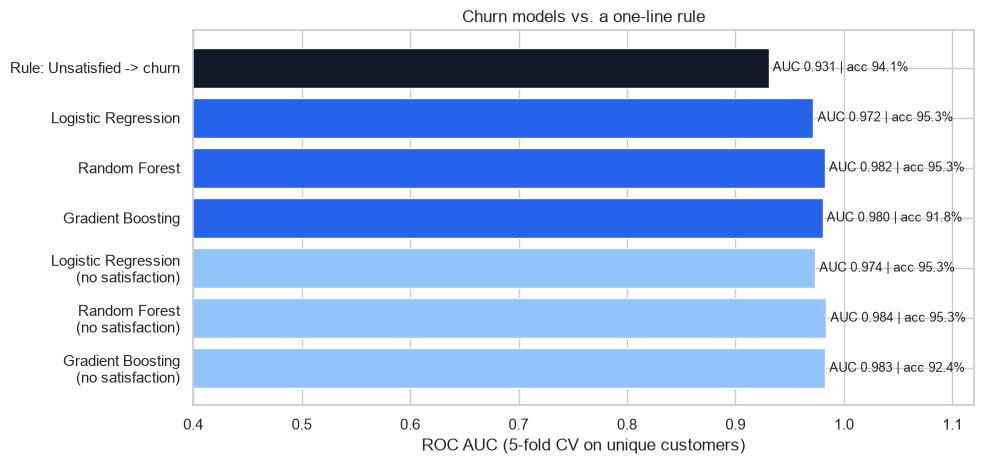

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = res.copy()
plot_df["label"] = plot_df["Model"] + plot_df["Features"].map({"Rule": "", "All features": "",
                                                               "Without satisfaction": "\n(no satisfaction)"})
colors = plot_df["Features"].map({"Rule": "#111827", "All features": "#2563eb", "Without satisfaction": "#93c5fd"})
bars = ax.barh(plot_df["label"], plot_df["ROC AUC"], color=colors)
ax.bar_label(bars, labels=[f"AUC {a:.3f} | acc {b:.1%}" for a, b in zip(plot_df["ROC AUC"], plot_df["Accuracy"])], padding=3, fontsize=9)
ax.set_xlim(0.4, 1.12); ax.invert_yaxis(); ax.set_xlabel("ROC AUC (5-fold CV on unique customers)")
ax.set_title("Churn models vs. a one-line rule")
plt.tight_layout(); plt.savefig(SHOTS / "churn_models.png", dpi=110); plt.show()

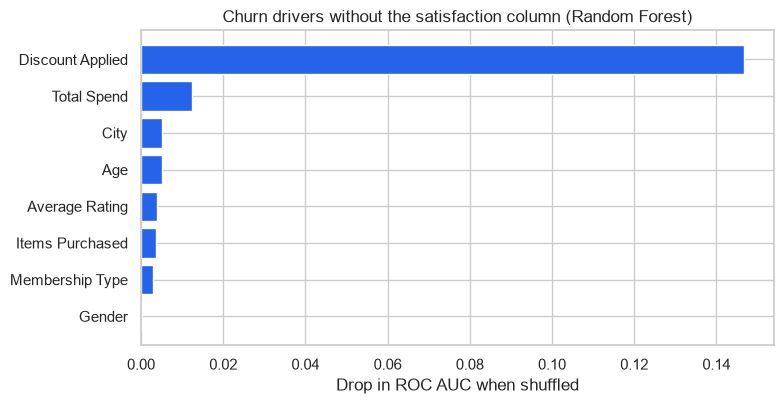

Discount_Applied    0.147
Total_Spend         0.012
City                0.005
Age                 0.005
Average_Rating      0.004
Items_Purchased     0.004
Membership_Type     0.003
Gender              0.000
dtype: float64

In [15]:
# What predicts churn when satisfaction is NOT available?
pipe = make_pipeline(make_prep(cat_no_sat, numf), RandomForestClassifier(n_estimators=300, max_depth=4,
                                                                         min_samples_leaf=5, random_state=SEED))
pipe.fit(data[cat_no_sat + numf], y)
imp = permutation_importance(pipe, data[cat_no_sat + numf], y, n_repeats=20, random_state=SEED, scoring="roc_auc")
importance = pd.Series(imp.importances_mean, index=cat_no_sat + numf).sort_values()
plt.figure(figsize=(8, 4.2))
plt.barh(importance.index.str.replace("_", " "), importance.values, color="#2563eb")
plt.xlabel("Drop in ROC AUC when shuffled"); plt.title("Churn drivers without the satisfaction column (Random Forest)")
plt.tight_layout(); plt.savefig(SHOTS / "churn_importance.png", dpi=110); plt.show()
importance.sort_values(ascending=False).round(3)

In [16]:
Path("results").mkdir(exist_ok=True)
res.round(4).to_csv("results/churn_model_results.csv", index=False)
summary.to_csv("results/customer_segments.csv")
facts = {"rows": int(len(df)), "unique_profiles": int(n_unique), "churn_rate": round(float(df["Churned"].mean()), 4),
         "best_k": int(best_k), "silhouette_k4": round(float(sil[list(ks).index(best_k)]), 3)}
Path("results/summary.json").write_text(json.dumps(facts, indent=2))
facts

{'rows': 350,
 'unique_profiles': 170,
 'churn_rate': 0.3543,
 'best_k': 4,
 'silhouette_k4': 0.543}

## 6. Key findings

1. **Data quality:** about half the rows are duplicate profiles, and `City` maps one-to-one to membership tier. Always audit a dataset before trusting high model scores.
2. **Gold members** spend about 2.8 times more than Bronze members, buy the most items, are the most satisfied, and almost never churn.
3. **Satisfaction is the churn signal:** every *Unsatisfied* customer churned. The one-line rule "Unsatisfied → churn" reaches 94% accuracy on unique customers, and the ML models only improve this to about 95% (ROC AUC about 0.98). The practical recommendation is to **act on satisfaction scores first**.
4. **Discounts mark at-risk customers:** about 70% of customers who received a discount churned, against about 1% of those who didn't. Without satisfaction data, *Discount_Applied* is by far the strongest predictor. Discounts here look like a reaction to disengagement rather than a cure.
5. **Segmentation** finds four actionable groups. VIP Gold spenders rarely churn. Silver members split into an engaged group (0% churn) and a lapsed group (100% churn). Older Bronze budget shoppers are a 50/50 risk, which makes them the best target for retention campaigns.